In [1]:
# To enable plotting graphs in Jupyter notebook
%matplotlib inline 

In [2]:
#!pip install missingpy

In [2]:
# The data lies in the following URL.
#url = "https://archive.ics.uci.edu/ml/machine-learning-databases/pima-indians-diabetes/pima-indians-diabetes.data"

# Since it is a data file with no header, we will supply the column names which have been obtained from the above URL 
# Create a python list of column names called "names"

colnames = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']

#pima_df = pd.read_csv(url, names= colnames)
#pima_df.head(2)

In [3]:
#Load the file from local directory using pd.read_csv which is a special form of read_table
#while reading the data, supply the "colnames" list
import pandas as pd
pima_df = pd.read_csv("pima-indians-diabetes.data", names= colnames)

In [4]:
pima_df.head()

,preg,plas,pres,skin,test,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
pima_df['class'] = pima_df['class'].replace(1, "Y")
pima_df['class'] = pima_df['class'].replace(0, "N")

In [6]:

nrows , ncols = pima_df.shape

pima_df_missing = [0,0,0,0,0,0,0]
for i in range(0, nrows-1):
    for j in range(1, ncols-1):
        if (pima_df.iloc[i,j] == 0):
            pima_df_missing[j-1] = pima_df_missing[j-1] + 1 # pima_df.iloc[i,:]
            



In [7]:
pima_df_missing

[5, 35, 227, 373, 11, 0, 0]

In [8]:
missing_colnames = ['plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age']
pima_df_missing_df =  pd.DataFrame(pima_df_missing , missing_colnames)
pima_df_missing_df

,0
plas,5
pres,35
skin,227
test,373
mass,11
pedi,0
age,0


In [32]:
import seaborn as sns
import numpy as np

from missingpy import KNNImputer
imputer = KNNImputer(n_neighbors=9, weights="uniform" , col_max_missing=1)

In [33]:
pima_missing.iloc[0,0]

148.0

In [34]:
pima_missing = pima_df.drop('preg' , axis=1)
pima_missing = pima_missing.drop('class' , axis=1)
nrows , ncols = pima_missing.shape

for i in range(0, nrows-1):
    for j in range(0, ncols-1):
        if (pima_missing.iloc[i,j] == 0):
            pima_missing.iloc[i,j] = np.NaN

In [35]:
pima_missing.head()

,plas,pres,skin,test,mass,pedi,age
0,148.0,72.0,35.0,NaN,33.6,0.627,50
1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,183.0,64.0,NaN,NaN,23.3,0.672,32
3,89.0,66.0,23.0,94.0,28.1,0.167,21
4,137.0,40.0,35.0,168.0,43.1,2.288,33


In [36]:
pima_df_imputed =  pd.DataFrame(imputer.fit_transform(pima_missing) )

pima_missing.head()

d:\Anaconda3\lib\site-packages\missingpy\knnimpute.py:224: UserWarning: There are rows with more than 50.0% missing values. These rows are not included as donor neighbors.
  .format(self.row_max_missing * 100))
d:\Anaconda3\lib\site-packages\missingpy\knnimpute.py:282: UserWarning: There are rows with more than 50.0% missing values. The missing features in these rows are imputed with column means.
  .format(self.row_max_missing * 100))
d:\Anaconda3\lib\site-packages\sklearn\utils\validation.py:432: DeprecationWarning: 'warn_on_dtype' is deprecated in version 0.21 and will be removed in 0.23. Don't set `warn_on_dtype` to remove this warning.
  DeprecationWarning)
d:\Anaconda3\lib\site-packages\sklearn\utils\validation.py:432: DeprecationWarning: 'warn_on_dtype' is deprecated in version 0.21 and will be removed in 0.23. Don't set `warn_on_dtype` to remove this warning.
  DeprecationWarning)


,plas,pres,skin,test,mass,pedi,age
0,148.0,72.0,35.0,NaN,33.6,0.627,50
1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,183.0,64.0,NaN,NaN,23.3,0.672,32
3,89.0,66.0,23.0,94.0,28.1,0.167,21
4,137.0,40.0,35.0,168.0,43.1,2.288,33


In [37]:
pima_df_imputed.head()

,0,1,2,3,4,5,6
0,148.0,72.0,35.000000,168.888889,33.6,0.627,50.0
1,85.0,66.0,29.000000,67.444444,26.6,0.351,31.0
2,183.0,64.0,25.888889,180.222222,23.3,0.672,32.0
3,89.0,66.0,23.000000,94.000000,28.1,0.167,21.0
4,137.0,40.0,35.000000,168.000000,43.1,2.288,33.0


In [38]:
# replace the missing values in pima_df with median value :Note, we do not need to specify the column names
# every column's missing value is replaced with that column's median respectively

pima_df_imputed['preg'] = pima_df['preg']
pima_df_imputed['class'] = pima_df['class']

In [39]:
pima_df_imputed.columns = ['plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age' , 'preg', 'class']

In [40]:
#Lets analysze the distribution of the various attributes
pima_df_imputed.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
plas,768.0,121.692853,30.453818,44.000,99.750000,117.000000,140.250000,199.00
pres,768.0,72.368276,12.154903,24.000,64.000000,72.000000,80.000000,122.00
skin,768.0,29.143181,9.249818,7.000,23.000000,29.153420,34.472222,99.00
test,768.0,152.519781,95.725886,0.000,89.861111,136.388889,188.027778,846.00
mass,768.0,32.452332,6.877359,18.200,27.500000,32.400000,36.600000,67.10
pedi,768.0,0.471876,0.331329,0.078,0.243750,0.372500,0.626250,2.42
age,768.0,33.240885,11.760232,21.000,24.000000,29.000000,41.000000,81.00
preg,768.0,3.845052,3.369578,0.000,1.000000,3.000000,6.000000,17.00


In [41]:
pima_df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
preg,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
plas,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
pres,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
skin,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
test,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
mass,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
pedi,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00


In [42]:
pima_df['class'] = pima_df['class'].replace(1, "Y")
pima_df['class'] = pima_df['class'].replace(0, "N")

pima_df_imputed['class'] = pima_df_imputed['class'].replace(1, "Y")
pima_df_imputed['class'] = pima_df_imputed['class'].replace(0, "N")

# Let us look at the target column which is 'class' to understand how the data is distributed amongst the various values
print(pima_df.groupby(["class"]).count())
print(pima_df_imputed.groupby(['class']).count())

# Most are not diabetic. The ratio is almost 1:2 in favor or class 0.  The model's ability to predict class 0 will 
# be better than predicting class 1. 

       preg  plas  pres  skin  test  mass  pedi  age
class                                               
N       500   500   500   500   500   500   500  500
Y       268   268   268   268   268   268   268  268
       plas  pres  skin  test  mass  pedi  age  preg
class                                               
N       500   500   500   500   500   500  500   500
Y       268   268   268   268   268   268  268   268


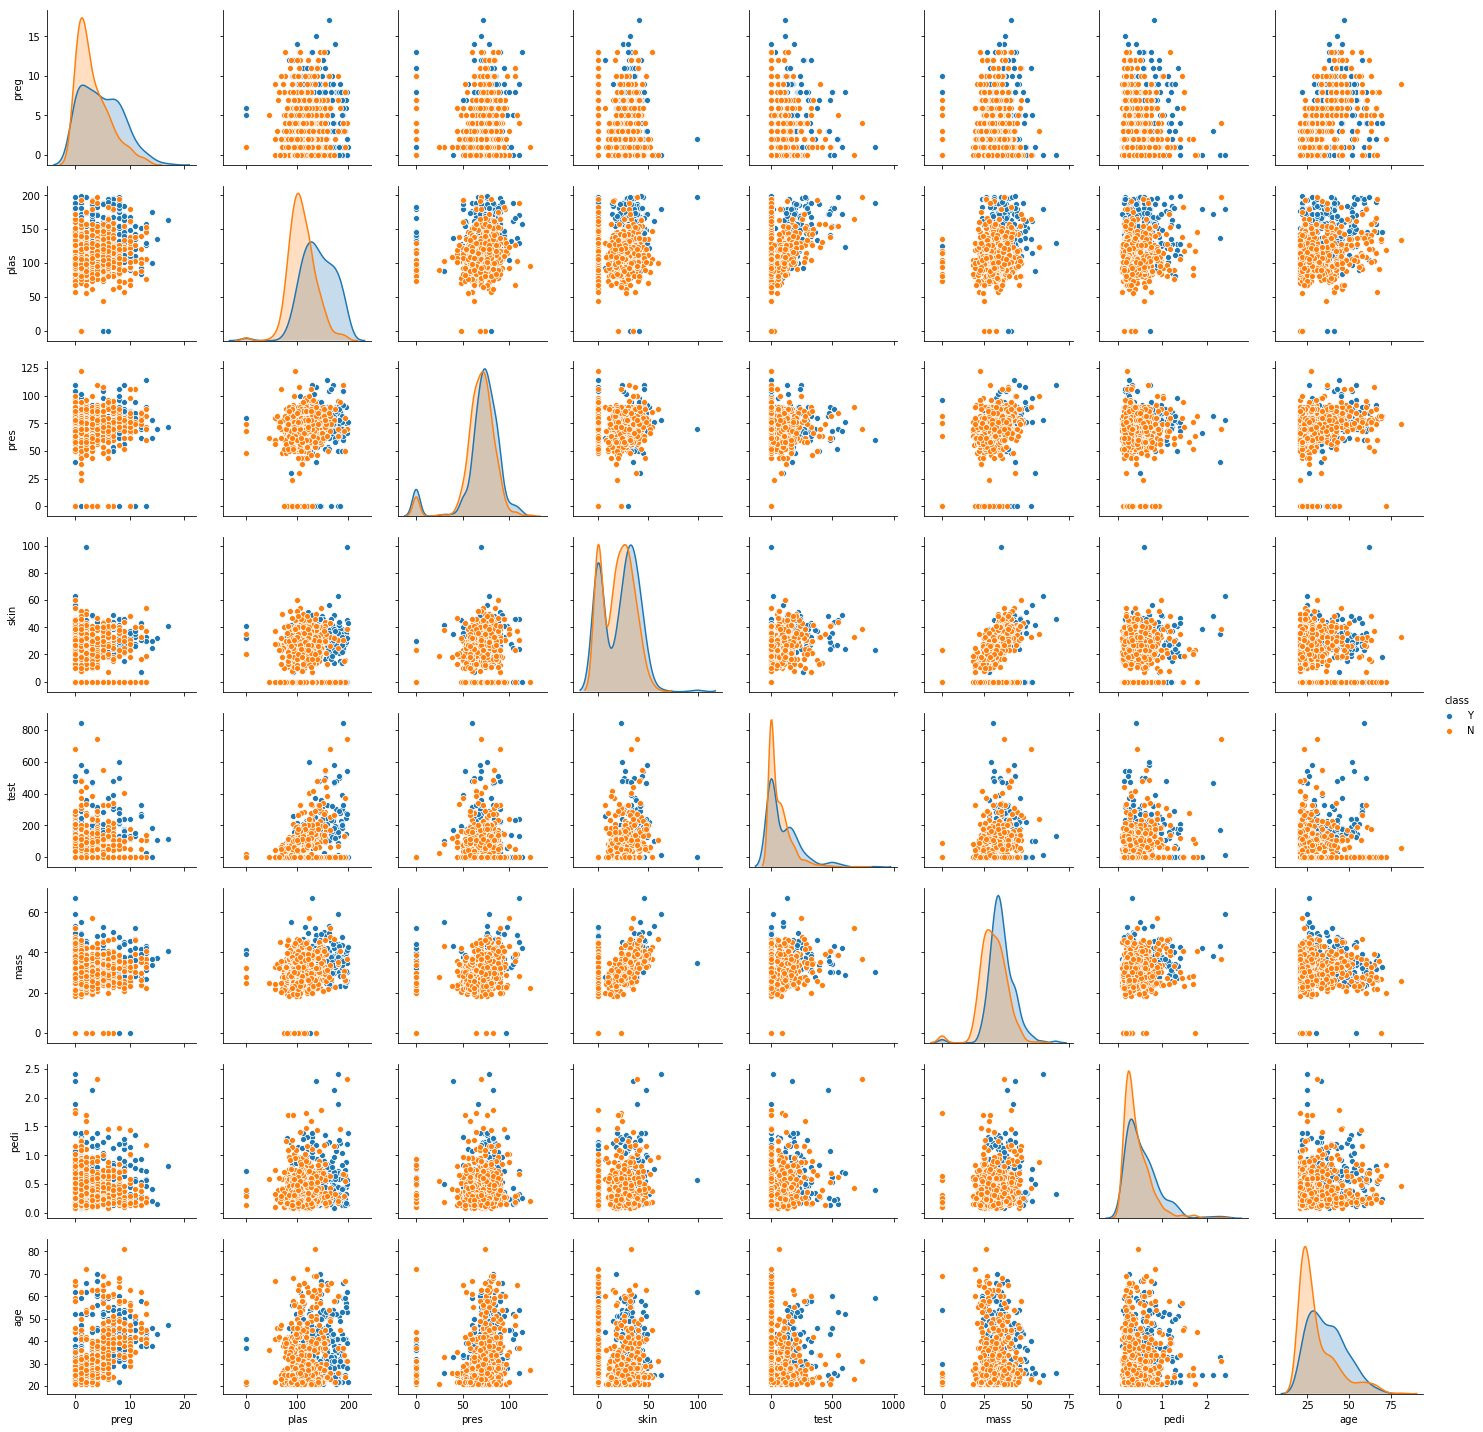

In [43]:
# Pairplot using sns

sns.pairplot(pima_df, hue = 'class')

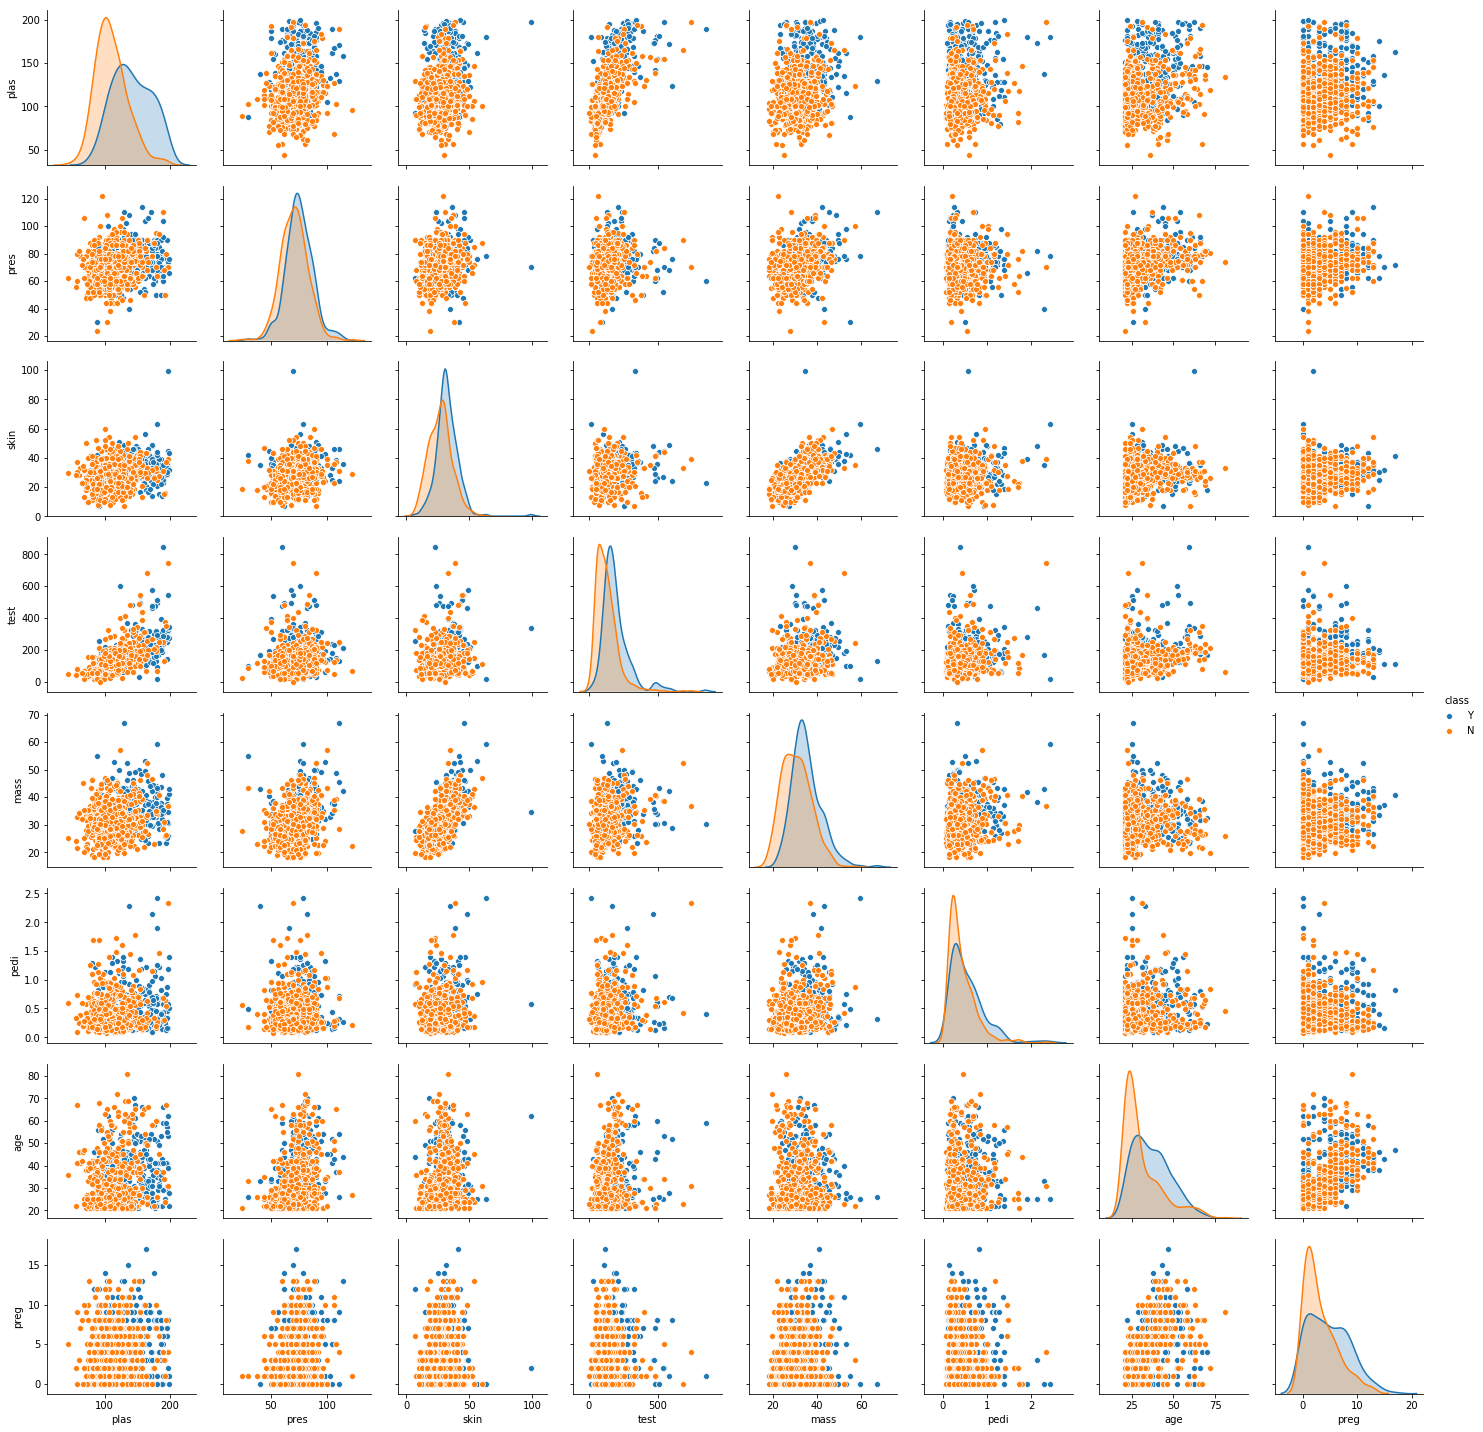

In [44]:
sns.pairplot(pima_df_imputed, hue = 'class')

In [45]:
from scipy.stats import zscore

colnames = ['plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age' , 'preg', 'class']

pima_df_z = pima_df_imputed[colnames[0:8]].apply(zscore)  # convert all attributes to Z scale 
pima_df_z['class'] = pima_df_imputed['class']

In [46]:
pima_df_z.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
plas     768 non-null float64
pres     768 non-null float64
skin     768 non-null float64
test     768 non-null float64
mass     768 non-null float64
pedi     768 non-null float64
age      768 non-null float64
preg     768 non-null float64
class    768 non-null object
dtypes: float64(8), object(1)
memory usage: 54.1+ KB


In [47]:
from sklearn.model_selection import train_test_split

array = pima_df_z.values
X = array[:,0:8] # select all rows and first 8 columns which are the attributes
Y = array[:,8]   # select all rows and the 8th column which is the classification "Yes", "No" for diabeties
test_size = 0.30 # taking 70:30 training and test set
seed = 7  # Random numbmer seeding for reapeatability of the code
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=test_size, random_state=seed)

In [48]:
from sklearn.neighbors import KNeighborsClassifier

NNH = KNeighborsClassifier(n_neighbors= 13)

NNH.fit(X_train, y_train)

KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
                     metric_params=None, n_jobs=None, n_neighbors=13, p=2,
                     weights='uniform')

In [49]:
predicted_labels = NNH.predict(X_test)
NNH.score(X_test, y_test)

0.7532467532467533

In [50]:
# calculate accuracy measures and confusion matrix
from sklearn import metrics

print(pd.DataFrame(metrics.confusion_matrix(y_test, predicted_labels, labels=["Y" ,"N"]), index=['true:yes', 'true:no'], columns=['pred:yes', 'pred:no']))

          pred:yes  pred:no
true:yes        52       32
true:no         25      122


In [51]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

# creating odd list of K for KNN
myList = list(range(1,50))


# empty list that will hold cv scores
cv_scores = []
k_neighbors = []

# perform 10-fold cross validation
for k in myList:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=10, scoring='accuracy')
    cv_scores.append(scores.mean())
    k_neighbors.append(k)


MSE = [1 - x for x in cv_scores]
min(MSE)
MSE.index(min(MSE))
best_k = myList[MSE.index(min(MSE))]
print ("The optimal number of neighbors is %d" % best_k)

The optimal number of neighbors is 13


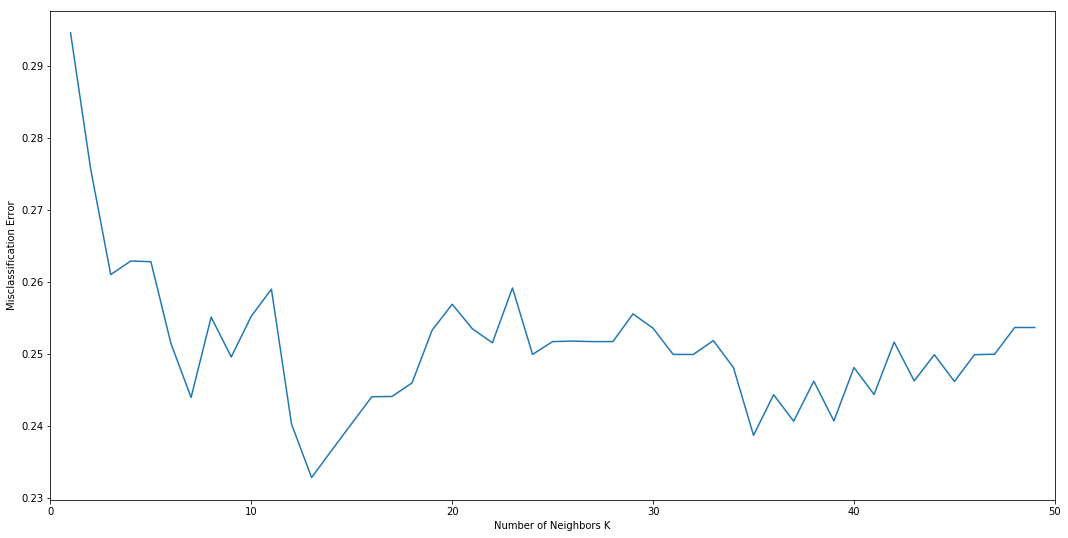

In [52]:
%matplotlib inline 
import matplotlib.pyplot as plt

fig_size = plt.rcParams["figure.figsize"]
fig_size[0] = 18
fig_size[1] = 9
plt.rcParams["figure.figsize"] = fig_size

plt.xlim(0,50)


# plot misclassification error vs k
plt.plot(k_neighbors, MSE)



plt.xlabel('Number of Neighbors K')
plt.ylabel('Misclassification Error')
plt.show()

In [53]:
knn = KNeighborsClassifier(n_neighbors=13)
knn.fit(X_train, y_train)
y_predict = knn.predict(X_test)


In [54]:
from sklearn import metrics

print(pd.DataFrame(metrics.confusion_matrix(y_test, y_predict, labels=["Y" ,"N"]), index=['true:yes', 'true:no'], columns=['pred:yes', 'pred:no']))

          pred:yes  pred:no
true:yes        52       32
true:no         25      122
